# 11 — Real global data on the globe

The other globe notebooks build the *base map*; this one drapes **real, whole-world datasets** over the globe with the projected-map API. Both datasets are **US-Government public domain**, and both are committed under `examples/data/global/`, so the notebook runs with no network at all:

- **ETOPO global relief & bathymetry** (NOAA, served downsampled by the [CoastWatch ERDDAP](https://coastwatch.pfeg.noaa.gov/erddap/)) — a single field from the deep trenches (about -10 km) to the high peaks (about +8 km), so the whole globe is data. Section 1 masks it to land to show the other case: a land-only field, where the `ocean()` disc shows through the sea.
- **NCEP/NCAR monthly mean air temperature** (NOAA PSL, 2.5 degrees) — 12 global grids, Jan..Dec, covering ocean as well as land.

The data is reprojected to each display CRS by **pyramids**, drawn on a plain axes by **cleopatra**, and framed into a globe by Digital-Earth — `field` / `contours` / `pcolormesh` all work on a projection.

> See `examples/data/ATTRIBUTION.md` for the exact sources, resolutions and citations.

## Read the committed data

Both grids are read straight from the checkout — there is nothing to fetch.

In [1]:
from pathlib import Path

# The global rasters are committed under examples/data/global/, so this notebook runs offline.
# ETOPO180 relief resampled to 0.5 deg, and the NCEP/NCAR 2.5 deg monthly temperature climatology.
# Both are US-Government public domain; see examples/data/ATTRIBUTION.md for sources and citations.
CACHE = Path('../../examples/data/global')

RELIEF = CACHE / 'etopo_relief.tif'
TAVG = sorted(CACHE.glob('ncep_tavg_*.tif'))      # 12 monthly grids, Jan..Dec
print('relief:', RELIEF.name)
print('temperature months:', len(TAVG))

relief: etopo_relief.tif
temperature months: 12


## Read with pyramids

Load the global rasters as `Dataset`s and define a graceful-coastlines helper.

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from pyramids.dataset import Dataset, GeoReference
from digitalearth.static import Map; from digitalearth.static.view import projections

NODATA = -9999.0

# A land-only elevation grid, derived from the committed relief: everything at or below sea level
# becomes nodata. That is what section 1 wants - a field with a hole where the ocean is, so the
# ocean() disc shows through it - while sections 4 onward use the full relief, sea floor included.
_relief = Dataset.read_file(str(RELIEF))
_vals = np.asarray(_relief.read_array(band=0), dtype='float32')
_vals = np.where(np.isclose(_vals, _relief.no_data_value[0]), np.nan, _vals)
elevation = Dataset.from_array(
    np.where(np.isfinite(_vals) & (_vals > 0.0), _vals, NODATA),
    geo_ref=GeoReference(geo=_relief.geotransform, epsg=_relief.epsg),
    no_data_value=NODATA,
)
jan = Dataset.read_file(str(TAVG[0]))
jul = Dataset.read_file(str(TAVG[6]))
print('elevation grid:', elevation.rows, 'x', elevation.columns, 'EPSG', elevation.epsg)
print('temperature grid:', jul.rows, 'x', jul.columns, 'EPSG', jul.epsg)

def context(m, *, coast=True):
    """Add coastlines if Natural Earth is reachable; never raise (keeps the notebook running offline)."""
    if not coast:
        return
    try:
        m.coastlines(resolution='110m')
    except Exception as exc:
        print('coastlines unavailable:', type(exc).__name__)

elevation grid: 360 x 720 EPSG 4326
temperature grid: 72 x 144 EPSG 4326


## ETOPO relief & bathymetry (NOAA ERDDAP)

ERDDAP serves ETOPO downsampled **server-side** (a stride on the 1-arc-minute grid) as an **ESRI-ASCII** grid — a plain-text raster — so we never download the full 466 MB file. We parse the numeric grid with **numpy** and build the raster with **pyramids** `Dataset.from_array`: pyramids is the GIS engine (CRS, reprojection, plotting), numpy just reads numbers from a text file. The result is a global relief field whose **negative** values are ocean depth.

In [3]:
import numpy as np

# ETOPO180 relief. It arrives from NOAA ERDDAP as a 12 MB ESRI-ASCII grid; the committed copy is
# that grid resampled to 0.5 deg and written as a GeoTIFF, which reads in one call and carries its
# own nodata so the ocean floor does not have to be masked by hand.
relief = Dataset.read_file(str(CACHE / 'etopo_relief.tif'))
vals = np.asarray(relief.read_array(band=0), float)
vals = vals[vals != relief.no_data_value[0]]
print('relief grid:', relief.rows, 'x', relief.columns, 'EPSG', relief.epsg)
print(f'range: {vals.min():.0f} m (deep ocean) .. {vals.max():.0f} m (peaks)')

relief grid: 360 x 720 EPSG 4326
range: -8264 m (deep ocean) .. 5627 m (peaks)


## 1. Global elevation on an orthographic globe

`ocean()` fills the disc, `field` draws the reprojected DEM (ocean cells are nodata, so the disc shows through the sea), and `coastlines()` + `graticule()` finish it. `colorbar()` adds the elevation scale.

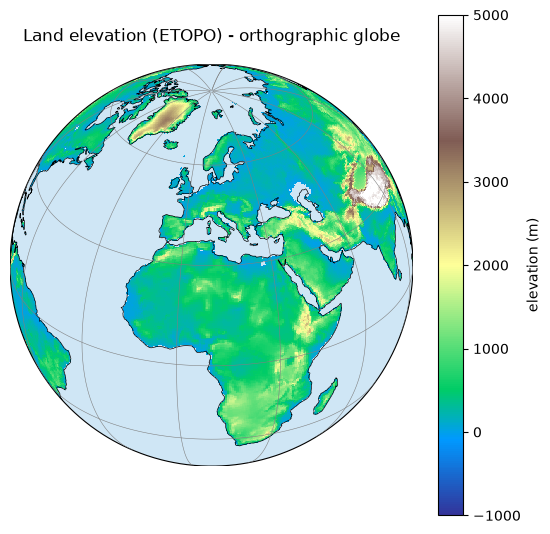

In [4]:
m = Map(crs=projections.orthographic(lon=10, lat=30), globe=True, figsize=(6.5, 6.5))
m.ocean()
m.field(elevation, cmap='terrain', vmin=-1000, vmax=5000)
context(m)
m.graticule(lon_step=30, lat_step=30)
m.set_global()
m.colorbar(label='elevation (m)')
m.set_title('Land elevation (ETOPO) - orthographic globe')
m.render()
m.fig;

## 2. July temperature — filled contours

`contours` of the July mean temperature over a globe centred on Asia. The ocean disc shows through where the land grid is nodata.

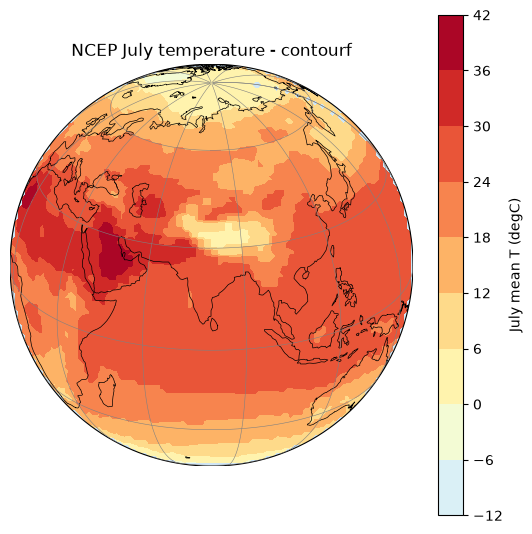

In [5]:
m = Map(crs=projections.orthographic(lon=80, lat=25), globe=True, figsize=(6.5, 6.5))
m.ocean()
m.contours(jul, cmap='RdYlBu_r', vmin=-40, vmax=40, filled=True)
context(m)
m.graticule(lon_step=30, lat_step=30)
m.set_global()
m.colorbar(label='July mean T (degC)')
m.set_title('NCEP July temperature - contourf')
m.render()
m.fig;

## 3. Whole-world projections

The same data on the two equal-ish world projections. **Robinson** with `pcolormesh`, **Mollweide** with `contours` — both framed and set to the full domain.

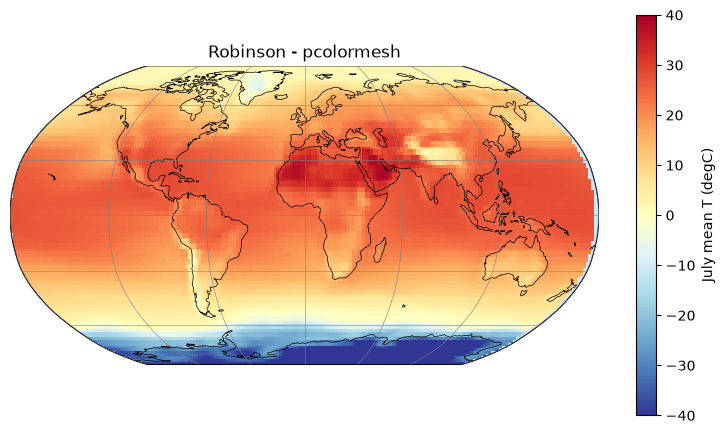

In [6]:
m = Map(crs=projections.robinson(lon=0), globe=True, figsize=(9.5, 5.2))
m.ocean()
m.pcolormesh(jul, cmap='RdYlBu_r', vmin=-40, vmax=40)
context(m)
m.graticule(lon_step=60, lat_step=30)
m.set_global()
m.colorbar(label='July mean T (degC)')
m.set_title('Robinson - pcolormesh')
m.render()
m.fig;

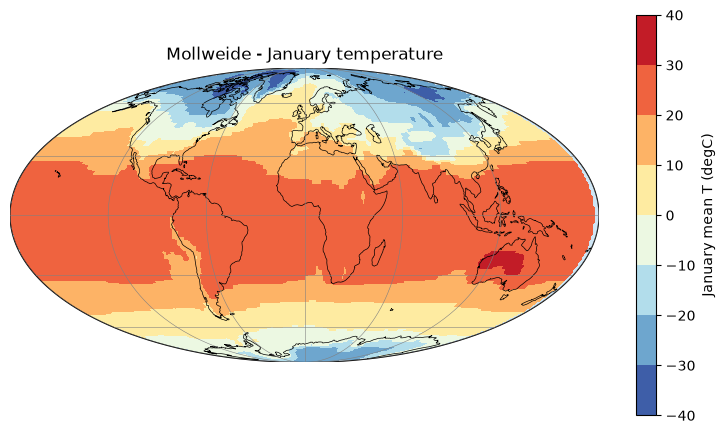

In [7]:
m = Map(crs=projections.mollweide(lon=0), globe=True, figsize=(9.5, 5.2))
m.ocean()
m.contours(jan, cmap='RdYlBu_r', vmin=-40, vmax=40, filled=True)
context(m)
m.graticule(lon_step=60, lat_step=30)
m.set_global()
m.colorbar(label='January mean T (degC)')
m.set_title('Mollweide - January temperature')
m.render()
m.fig;

## 4. Seasonal contrast — two globes side by side

`Map` accepts an existing `ax`, so several globes fit in one figure. January vs July temperature on matching orthographic views shows the hemispheres swapping warmth.

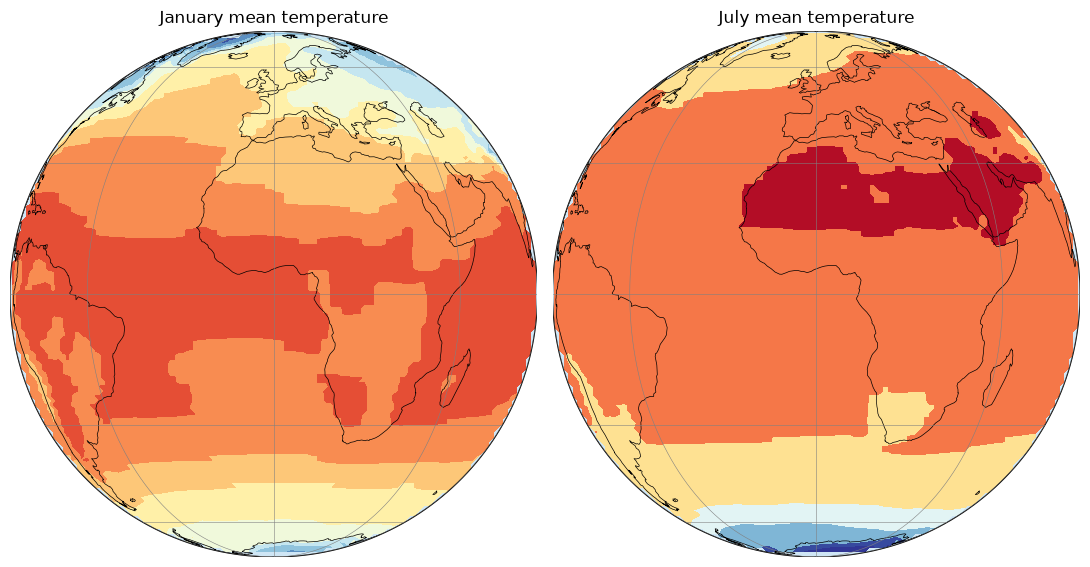

In [8]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(11, 5.6))
for ax, month, label in [(axL, jan, 'January'), (axR, jul, 'July')]:
    m = Map(crs=projections.orthographic(lon=0, lat=0), globe=True, ax=ax)
    m.ocean()
    m.contours(month, cmap='RdYlBu_r', vmin=-40, vmax=40, filled=True)
    context(m)
    m.graticule(lon_step=45, lat_step=30)
    m.set_global()
    m.set_title(f'{label} mean temperature')
    m.render()
fig.tight_layout(); fig;

## 5. Centre the globe on a place

The orthographic **centre** `(lon, lat)` fixes where the globe faces — change those two numbers to point it anywhere. Below, the same ETOPO relief is shown from four centres. To zoom into a region of a centred globe instead of the whole disc, use `set_domain(name)` (a named region) or `set_bounds(...)`. `set_bounds` takes `(west, south, east, north)` in the display CRS — the same order on every tier, and the one `Bounds` holds its own numbers in — or, better, a `Bounds`, which names the CRS as well as the ordering and is reprojected for you: `set_bounds(Bounds.from_bbox([xmin, ymin, xmax, ymax], crs=4326))`.

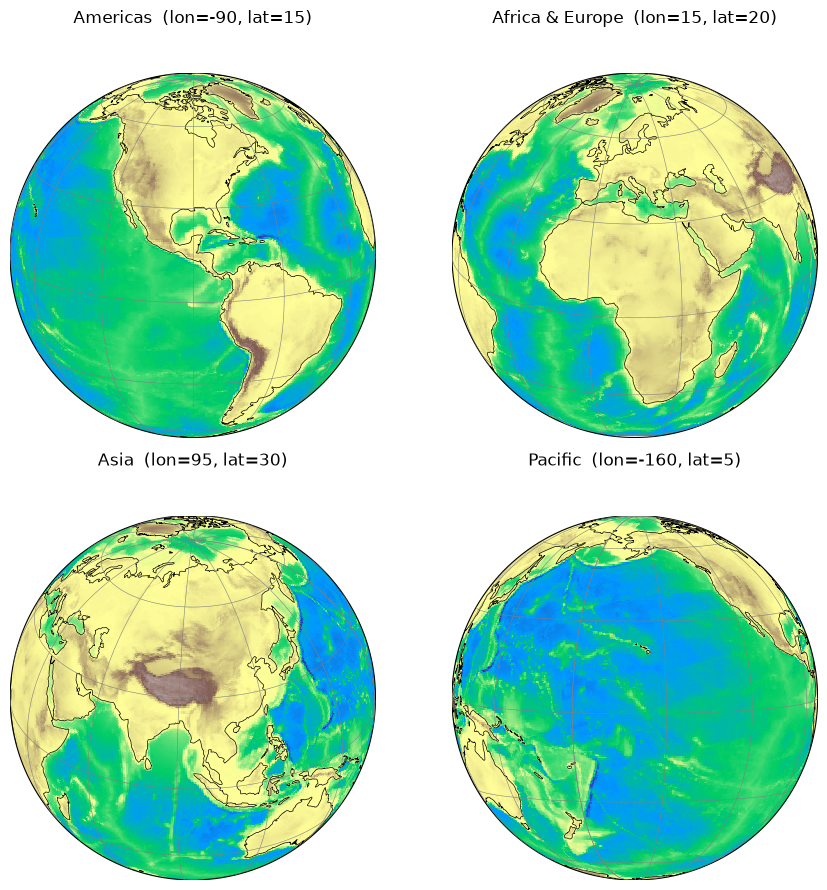

In [9]:
places = [('Americas', -90, 15), ('Africa & Europe', 15, 20),
          ('Asia', 95, 30), ('Pacific', -160, 5)]
fig, axs = plt.subplots(2, 2, figsize=(9, 9))
for ax, (name, lon, lat) in zip(axs.ravel(), places):
    m = Map(crs=projections.orthographic(lon=lon, lat=lat), globe=True, ax=ax)
    m.field(relief, cmap='terrain', vmin=-8000, vmax=8000)
    context(m)
    m.graticule(lon_step=30, lat_step=30)
    m.set_global()
    m.set_title(f'{name}  (lon={lon}, lat={lat})')
    m.render()
fig.tight_layout(); fig;

Zoom into a region of a centred globe — centre on Europe, then `set_domain('europe')` to crop the view to Europe's bounds (the data stays clipped to the projection disc):

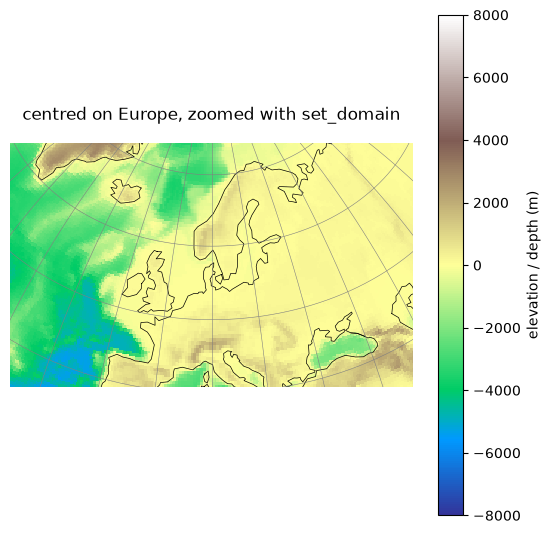

In [10]:
m = Map(crs=projections.orthographic(lon=10, lat=50), globe=True, figsize=(6.5, 6.5))
m.field(relief, cmap='terrain', vmin=-8000, vmax=8000)
context(m)
m.graticule(lon_step=10, lat_step=10)
m.set_global()
m.colorbar(label='elevation / depth (m)')
m.set_title('centred on Europe, zoomed with set_domain')
m.render()
m.set_domain('europe')   # crop the view to the region's bounds
m.fig;

## 6. ETOPO relief & bathymetry on the globe

Because ETOPO carries ocean depth, the **whole globe is data** — no `ocean()` needed. A `terrain` colormap spanning +/- 8000 m renders the sea floor in blues and the land in greens/browns. Coastlines trace the zero contour.

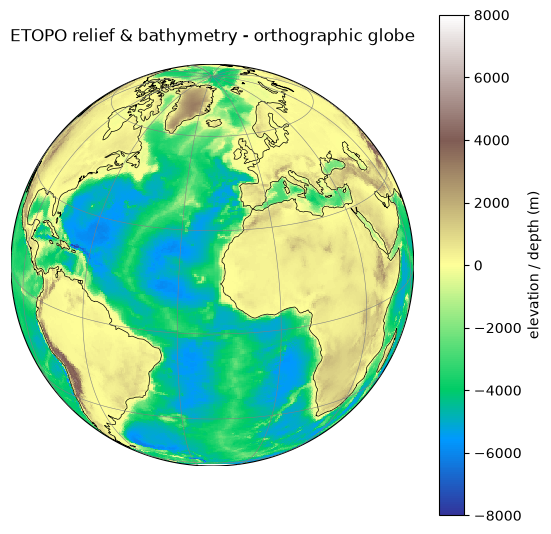

In [11]:
m = Map(crs=projections.orthographic(lon=-20, lat=20), globe=True, figsize=(6.5, 6.5))
m.field(relief, cmap='terrain', vmin=-8000, vmax=8000)
context(m)
m.graticule(lon_step=30, lat_step=30)
m.set_global()
m.colorbar(label='elevation / depth (m)')
m.set_title('ETOPO relief & bathymetry - orthographic globe')
m.render()
m.fig;

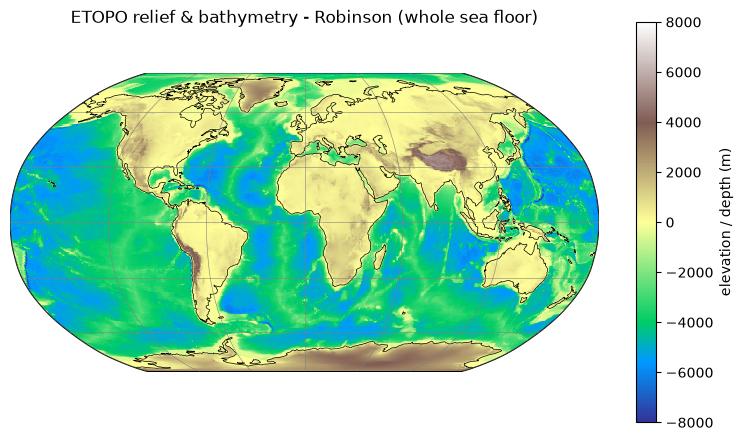

In [12]:
m = Map(crs=projections.robinson(lon=0), globe=True, figsize=(9.5, 5.2))
m.field(relief, cmap='terrain', vmin=-8000, vmax=8000)
context(m)
m.graticule(lon_step=60, lat_step=30)
m.set_global()
m.colorbar(label='elevation / depth (m)')
m.set_title('ETOPO relief & bathymetry - Robinson (whole sea floor)')
m.render()
m.fig;

## 7. Save a globe to PNG

`save()` applies the frame and writes the figure; the data and fills are clipped to the boundary in the file.

saved: C:\python-environments\worktrees\Digital-Earth\static-notebooks\docs\examples\global_elevation_globe.png | 112369 bytes


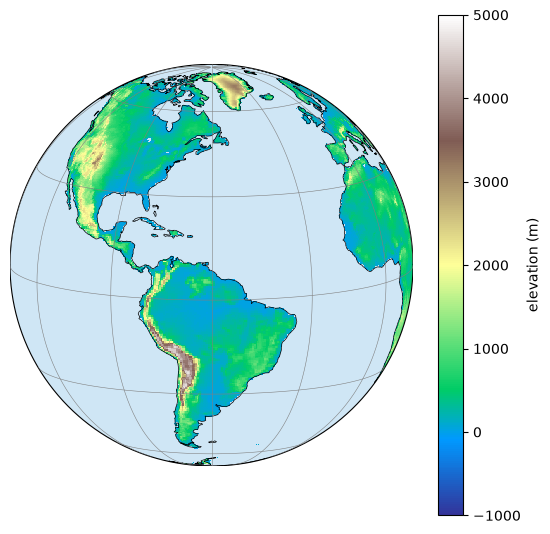

In [13]:
out = Path('global_elevation_globe.png')
m = Map(crs=projections.orthographic(lon=-60, lat=10), globe=True, figsize=(6.5, 6.5))
m.ocean()
m.field(elevation, cmap='terrain', vmin=-1000, vmax=5000)
context(m)
m.graticule(); m.set_global()
m.colorbar(label='elevation (m)')
m.save(str(out))
print('saved:', out.resolve(), '|', out.stat().st_size, 'bytes')
out.unlink()  # clean up the example artifact